# ARTI 502 — Experiment 7: Final Metrics, Plots & Confusion Matrix

**Complete Google Colab notebook** based on the team's CNN_BN. Same architecture and 30-epoch training settings, fixed stratified 45k Train / 5k Validation split, and the official 10k Test split.

**Assignment Task 5** asks for Train Loss, Test Loss, and Test Accuracy against Epoch. This version **records those three curves**, in addition to validation curves and final confusion matrices.

**Scientific protocol:** We choose the best checkpoint **only by Validation Accuracy** (Validation Loss breaks ties). The Test Set is evaluated at the end of each epoch strictly to produce the assignment's requested descriptive figures; its metrics are **never used for model selection, stopping, learning-rate changes, or hyperparameter tuning**. Repeated exposure to Test results still weakens the independence of that test estimate—report that limitation honestly. The official final test score corresponds to the validation-selected checkpoint.

**Important:** To obtain real per-epoch Test curves you **must rerun training** using this notebook, since the previous notebook did not save all epoch checkpoints or Test metrics. Earlier 91.71% is a *previous run's* score, not guaranteed for this rerun. Use `Runtime → Change runtime type → T4 GPU`, then `Run all`.


## Step 1 — CIFAR-10 download & transformations

- `train_transform`: the teammate's original RandomCrop + RandomHorizontalFlip + Normalize.
- `test_transform`: ToTensor + Normalize only (used for validation and test).

In [1]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms
from torch.utils.data import DataLoader

DATA_PATH = './cifar_data'
os.makedirs(DATA_PATH, exist_ok=True)

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=CIFAR_MEAN, std=CIFAR_STD),
])
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=CIFAR_MEAN, std=CIFAR_STD),
])
augmented_trainset = torchvision.datasets.CIFAR10(
    root=DATA_PATH, train=True, download=True, transform=train_transform
)
print('Official CIFAR-10 training images:', len(augmented_trainset))

100%|██████████| 170M/170M [09:48<00:00, 290kB/s]


Official CIFAR-10 training images: 50000


## Step 2 — Teammate's CNN_BN architecture (unchanged)

Three blocks with two convolution layers each, BatchNorm + MaxPooling. Fully connected classifier with Dropout 0.4.

In [2]:
def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(kernel_size=2, stride=2),
    )


class CNN_BN(nn.Module):
    def __init__(self):
        super(CNN_BN, self).__init__()

        # 32x32 -> 16x16 -> 8x8 -> 4x4
        self.features = nn.Sequential(
            conv_block(3, 64),
            conv_block(64, 128),
            conv_block(128, 256),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.4),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, 10),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

## Experiment 7 — CNN_BN: 30 epochs with Metrics Tracking

**Model settings unchanged:** 6 convolutional layers, BatchNorm, Flatten + FC, Dropout 0.4; RandomCrop + RandomHorizontalFlip; AdamW (max LR 0.002, weight decay 0.0005); OneCycleLR per minibatch; training label smoothing 0.1; batch size 128; 30 epochs.

**Data splits:** 45,000 training, 5,000 validation, 10,000 official test. Validation samples use deterministic transformations.

Each epoch logs Train, Validation, and Test results. **Best checkpoint chosen strictly using Validation**. Test curves are descriptive figures for the assignment, *not* a basis for choosing a model. The test set is separate from training/validation but repeatedly viewed in the report; it should not be called a fully untouched final test in this version.


In [3]:
# Experiment 7A — Reproducible 45k/5k split + untouched official 10k test set
import os
import json
import time
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

SEED_7 = 42
random.seed(SEED_7)
np.random.seed(SEED_7)
torch.manual_seed(SEED_7)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED_7)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR_7 = Path('exp7_validation_results')
OUTPUT_DIR_7.mkdir(parents=True, exist_ok=True)
BEST_MODEL_PATH_7 = OUTPUT_DIR_7 / 'exp7_best_validation_model.pt'

# Existing Task 4 dataset: train_transform = RandomCrop + Flip + Normalize.
# Validation must use deterministic test_transform (no random augmentation).
val_source7 = torchvision.datasets.CIFAR10(
    root=DATA_PATH, train=True, download=False, transform=test_transform
)
test_source7 = torchvision.datasets.CIFAR10(
    root=DATA_PATH, train=False, download=False, transform=test_transform
)

all_indices7 = np.arange(len(augmented_trainset))
train_idx7, val_idx7 = train_test_split(
    all_indices7,
    test_size=0.10,
    random_state=SEED_7,
    stratify=np.asarray(augmented_trainset.targets)
)
assert len(augmented_trainset) == 50_000 and len(val_source7) == 50_000
assert len(train_idx7) == 45_000 and len(val_idx7) == 5_000
assert set(train_idx7).isdisjoint(set(val_idx7))
assert len(set(train_idx7) | set(val_idx7)) == 50_000
assert len(test_source7) == 10_000
assert np.array_equal(np.asarray(augmented_trainset.targets), np.asarray(val_source7.targets))

train_set7 = Subset(augmented_trainset, train_idx7.tolist())
val_set7 = Subset(val_source7, val_idx7.tolist())

EPOCHS_7 = 30
BATCH_7 = 128
num_workers7 = 2 if os.name != 'nt' else 0

generator7 = torch.Generator().manual_seed(SEED_7)
train_loader7 = DataLoader(
    train_set7, batch_size=BATCH_7, shuffle=True, generator=generator7,
    num_workers=num_workers7, pin_memory=(device.type == 'cuda')
)
val_loader7 = DataLoader(
    val_set7, batch_size=BATCH_7, shuffle=False,
    num_workers=num_workers7, pin_memory=(device.type == 'cuda')
)
test_loader7 = DataLoader(
    test_source7, batch_size=BATCH_7, shuffle=False,
    num_workers=num_workers7, pin_memory=(device.type == 'cuda')
)

classes7 = list(test_source7.classes)
print(f'Device: {device} | Train: {len(train_set7):,} | Validation: {len(val_set7):,} | Test: {len(test_source7):,}')
print('Train/Validation overlap:', len(set(train_idx7) & set(val_idx7)))
print('Validation class counts:', np.bincount(np.asarray(val_source7.targets)[val_idx7]).tolist())

Device: cuda | Train: 45,000 | Validation: 5,000 | Test: 10,000
Train/Validation overlap: 0
Validation class counts: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


In [4]:
# Experiment 7B — Same CNN_BN training configuration; select best checkpoint by Validation
model_exp7 = CNN_BN().to(device)   # Same teammate architecture — unchanged
criterion_train7 = nn.CrossEntropyLoss(label_smoothing=0.1)
criterion_eval7 = nn.CrossEntropyLoss()
optimizer7 = optim.AdamW(model_exp7.parameters(), lr=2e-3, weight_decay=5e-4)
scheduler7 = optim.lr_scheduler.OneCycleLR(
    optimizer7, max_lr=2e-3, epochs=EPOCHS_7, steps_per_epoch=len(train_loader7)
)

@torch.no_grad()
def evaluate7(model, loader, criterion, return_predictions=False):
    model.eval()
    total_loss, total_correct, n = 0.0, 0, 0
    labels_all, predictions_all = [], []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = criterion(logits, y)
        bs = y.size(0)
        total_loss += loss.item() * bs
        total_correct += (logits.argmax(dim=1) == y).sum().item()
        n += bs
        if return_predictions:
            labels_all.append(y.cpu().numpy())
            predictions_all.append(logits.argmax(dim=1).cpu().numpy())
    assert n == len(loader.dataset) and n > 0, 'Incomplete evaluation: sample count mismatch.'
    result = (total_loss / n, 100.0 * total_correct / n)
    if return_predictions:
        return (*result, np.concatenate(labels_all), np.concatenate(predictions_all))
    return result

exp7_history = {'epoch': [], 'train_loss': [], 'train_accuracy': [],
                'val_loss': [], 'val_accuracy': [], 'test_loss': [], 'test_accuracy': [], 'learning_rate': []}
best_val_acc7, best_val_loss7, best_epoch7 = -1.0, float('inf'), None
start_time7 = time.time()

print('Experiment 7: 30 epochs | checkpoint selected ONLY on Validation | test curves logged for Task 5')
for epoch in range(1, EPOCHS_7 + 1):
    model_exp7.train()
    train_loss_sum, train_correct, train_count = 0.0, 0, 0
    for x, y in train_loader7:
        x, y = x.to(device), y.to(device)
        optimizer7.zero_grad(set_to_none=True)
        logits = model_exp7(x)
        loss = criterion_train7(logits, y)
        loss.backward()
        optimizer7.step()
        scheduler7.step()  # Same per-batch OneCycleLR schedule as teammate
        bs = y.size(0)
        train_loss_sum += loss.item() * bs
        train_correct += (logits.argmax(dim=1) == y).sum().item()
        train_count += bs

    assert train_count == len(train_set7)
    train_loss = train_loss_sum / train_count
    train_acc = 100.0 * train_correct / train_count
    val_loss, val_acc = evaluate7(model_exp7, val_loader7, criterion_eval7)
    # Task 5: record official test metrics for descriptive plots only.
    # Never use these values to select a checkpoint or tune hyperparameters.
    test_loss, test_acc = evaluate7(model_exp7, test_loader7, criterion_eval7)

    exp7_history['epoch'].append(epoch)
    exp7_history['train_loss'].append(train_loss)
    exp7_history['train_accuracy'].append(train_acc)
    exp7_history['val_loss'].append(val_loss)
    exp7_history['val_accuracy'].append(val_acc)
    exp7_history['test_loss'].append(test_loss)
    exp7_history['test_accuracy'].append(test_acc)
    exp7_history['learning_rate'].append(scheduler7.get_last_lr()[0])

    # Only validation determines the best checkpoint. Test values are logged ONLY for plots.
    if val_acc > best_val_acc7 or (val_acc == best_val_acc7 and val_loss < best_val_loss7):
        best_val_acc7, best_val_loss7, best_epoch7 = val_acc, val_loss, epoch
        torch.save({
            'model_state_dict': model_exp7.state_dict(),
            'best_epoch': best_epoch7,
            'validation_accuracy': best_val_acc7,
            'validation_loss': best_val_loss7,
            'seed': SEED_7,
        }, BEST_MODEL_PATH_7)

    pd.DataFrame(exp7_history).to_csv(OUTPUT_DIR_7 / 'exp7_epoch_metrics.csv', index=False)
    print(f'Epoch {epoch:02}/{EPOCHS_7} | '
          f'Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | '
          f'Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}% | '
          f'Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.2f}%')

exp7_time = time.time() - start_time7
print(f'Best Validation: {best_val_acc7:.2f}% at epoch {best_epoch7}')
print(f'Training time: {exp7_time:.1f} seconds')
print('Checkpoint:', BEST_MODEL_PATH_7)

Experiment 7: 30 epochs | checkpoint selected ONLY on Validation | test curves logged for Task 5
Epoch 01/30 | Train Loss: 1.7711 | Train Acc: 40.41% | Val Loss: 1.2823 | Val Acc: 54.72% | Test Loss: 1.3006 | Test Acc: 54.66%
Epoch 02/30 | Train Loss: 1.4614 | Train Acc: 56.50% | Val Loss: 0.9899 | Val Acc: 65.38% | Test Loss: 1.0119 | Test Acc: 64.59%
Epoch 03/30 | Train Loss: 1.3150 | Train Acc: 64.61% | Val Loss: 0.8799 | Val Acc: 70.24% | Test Loss: 0.9043 | Test Acc: 69.00%
Epoch 04/30 | Train Loss: 1.2339 | Train Acc: 69.01% | Val Loss: 0.8104 | Val Acc: 74.04% | Test Loss: 0.8268 | Test Acc: 73.54%
Epoch 05/30 | Train Loss: 1.1705 | Train Acc: 72.30% | Val Loss: 0.8323 | Val Acc: 73.46% | Test Loss: 0.8772 | Test Acc: 71.64%
Epoch 06/30 | Train Loss: 1.1173 | Train Acc: 75.07% | Val Loss: 1.0184 | Val Acc: 65.36% | Test Loss: 1.0334 | Test Acc: 65.41%
Epoch 07/30 | Train Loss: 1.0758 | Train Acc: 77.06% | Val Loss: 0.6691 | Val Acc: 79.96% | Test Loss: 0.6981 | Test Acc: 78.90%


In [5]:
# Experiment 7C — FINAL score for the checkpoint selected by VALIDATION (test evaluated again for confusion matrix)
assert BEST_MODEL_PATH_7.exists(), 'No best-validation checkpoint saved.'
try:
    checkpoint7 = torch.load(BEST_MODEL_PATH_7, map_location=device, weights_only=True)
except TypeError:  # older PyTorch without weights_only parameter
    checkpoint7 = torch.load(BEST_MODEL_PATH_7, map_location=device)
model_exp7.load_state_dict(checkpoint7['model_state_dict'])
assert checkpoint7['best_epoch'] == best_epoch7

# Test was already evaluated per epoch for the assignment curves. This pass evaluates the validation-selected checkpoint for final reporting.
final_test_loss7, final_test_acc7, y_true7, y_pred7 = evaluate7(
    model_exp7, test_loader7, criterion_eval7, return_predictions=True
)
assert len(y_true7) == len(y_pred7) == 10_000
assert set(np.unique(y_true7)) == set(range(10))
assert abs(final_test_acc7 - 100.0 * np.mean(y_true7 == y_pred7)) < 1e-10

final_summary7 = {
    'experiment': 'Exp 7 — CNN_BN with held-out validation',
    'train_samples': int(len(train_set7)),
    'validation_samples': int(len(val_set7)),
    'test_samples': int(len(test_source7)),
    'test_evaluated_each_epoch_for_assignment_plots': True,
    'epochs_run': int(EPOCHS_7),
    'best_epoch_by_validation': int(best_epoch7),
    'best_validation_accuracy_percent': float(best_val_acc7),
    'best_validation_loss': float(best_val_loss7),
    'final_test_accuracy_percent': float(final_test_acc7),
    'final_test_loss': float(final_test_loss7),
    'train_val_overlap': int(len(set(train_idx7) & set(val_idx7))),
    'training_time_seconds': float(exp7_time),
    'seed': int(SEED_7),
}
with open(OUTPUT_DIR_7 / 'exp7_final_results.json', 'w') as f:
    json.dump(final_summary7, f, indent=2)

print(f"Best Validation: {best_val_acc7:.2f}% (epoch {best_epoch7})")
print(f"FINAL Test Accuracy: {final_test_acc7:.2f}% on {len(y_true7):,} images")
print(f"FINAL Test Loss: {final_test_loss7:.4f}")
# Verify the final Test score matches the recorded Test accuracy at the validation-selected epoch.
assert abs(final_test_acc7 - exp7_history['test_accuracy'][best_epoch7 - 1]) < 1e-9
assert abs(final_test_loss7 - exp7_history['test_loss'][best_epoch7 - 1]) < 1e-4
print('PASS — final selected-checkpoint Test metrics agree with that epoch in the curve.')
print('Previous run: 91.71%; new run may differ. Original teammate run: 92.36%.')

Best Validation: 92.48% (epoch 29)
FINAL Test Accuracy: 91.71% on 10,000 images
FINAL Test Loss: 0.3219
PASS — final selected-checkpoint Test metrics agree with that epoch in the curve.
Previous run: 91.71%; new run may differ. Original teammate run: 92.36%.


## Metrics Tracking & Plotting — Your Final Section

This section is **your assignment deliverable**:

- Task 5's **Training Loss, Test Loss, and Test Accuracy plotted against epochs** (real metrics recorded after each epoch, not invented values).
- Extra: Train/Validation accuracy and loss learning curves, used to select the best epoch.
- Final Test metrics for the **validation-selected** checkpoint on all 10,000 test images.
- Confusion Matrix (counts and normalized), classification report, per-class F1 score, experiment comparison, exported CSV/PNG files.

The Test curves are *monitoring plots only*; never use them to select an epoch or alter experiments. Training loss is label-smoothed; Validation and Test loss use ordinary Cross-Entropy, so their absolute values are not directly comparable.


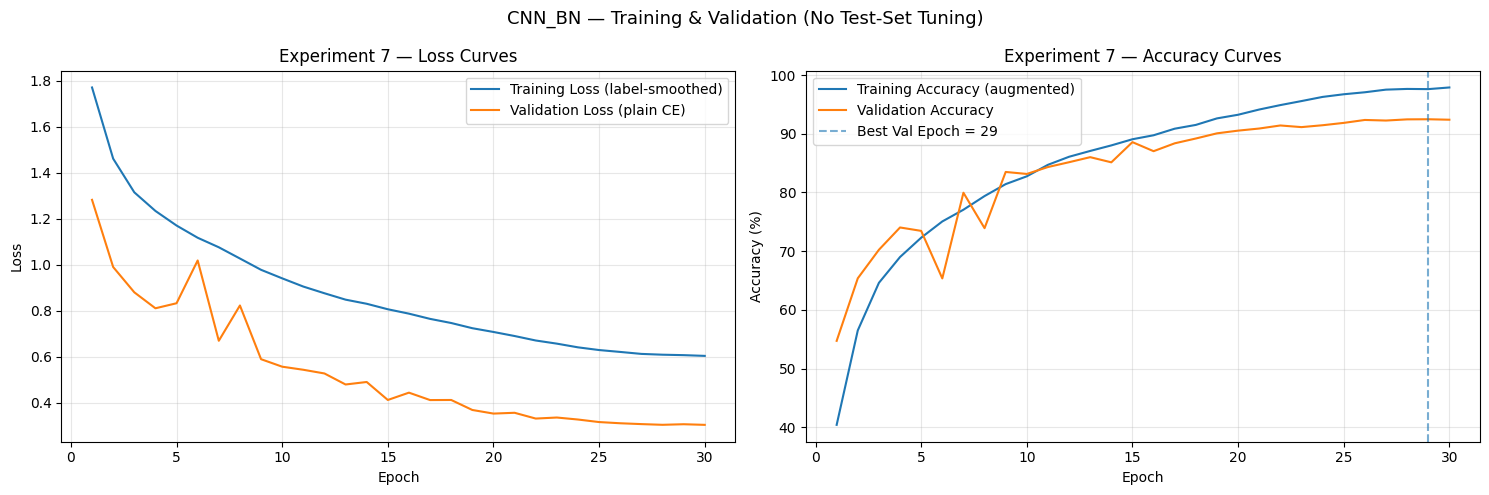

Saved train/validation curves + epoch_metrics.csv


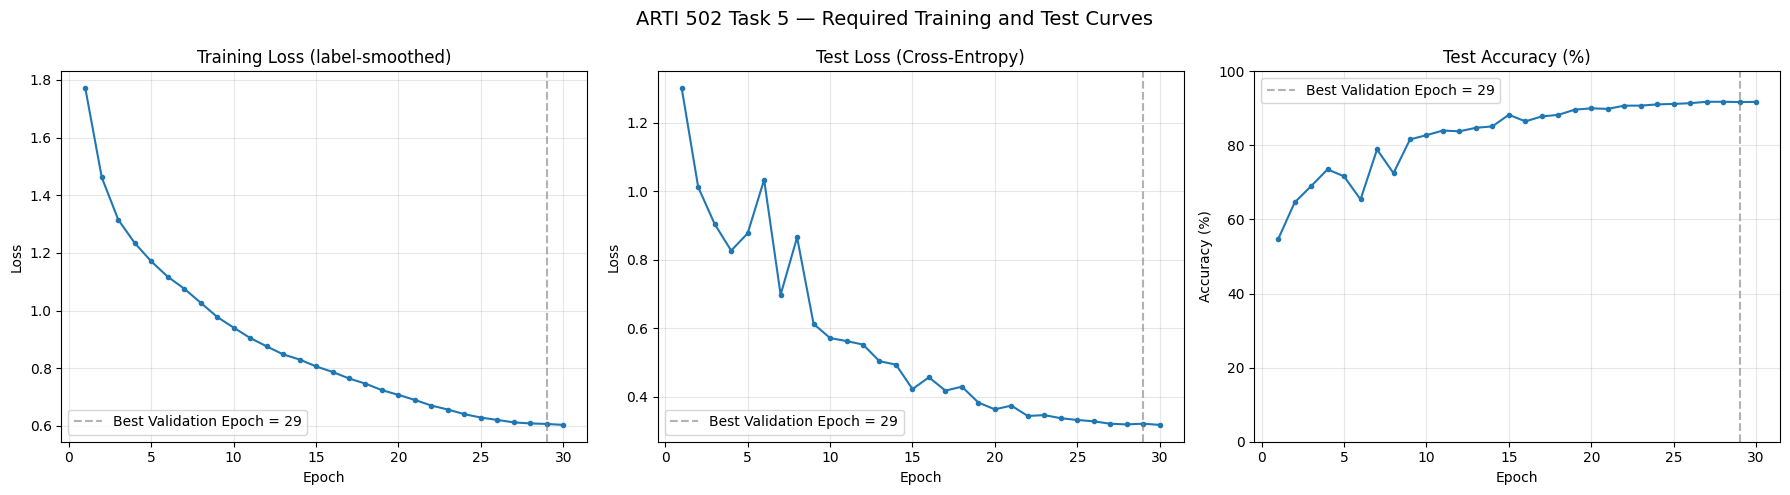

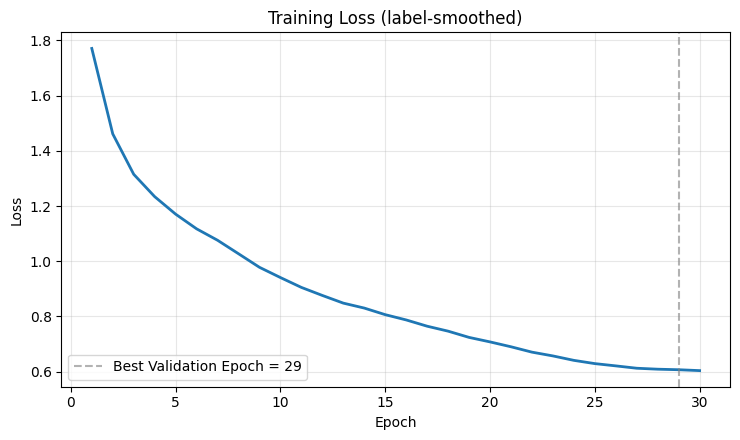

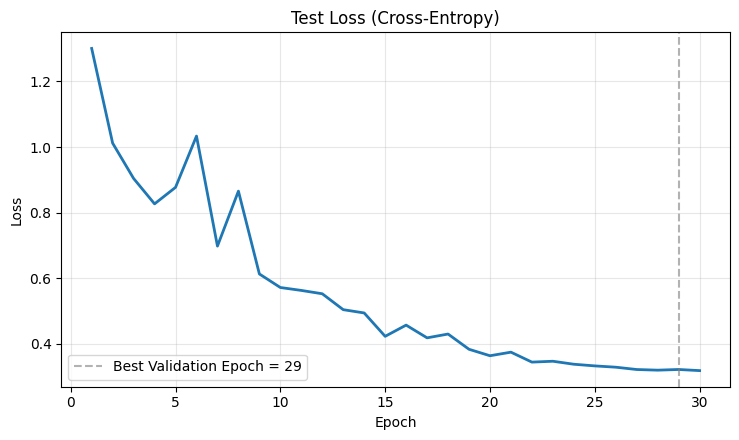

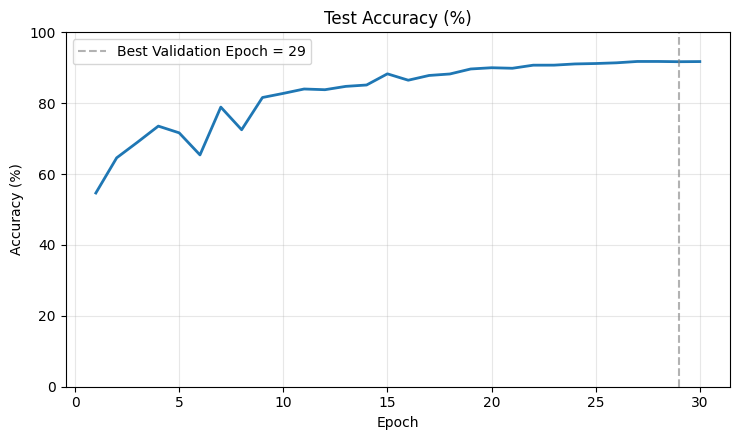

PASS — saved the three Task 5 plots, additional validation curves, and epoch_metrics.csv


In [6]:
# Metrics 1 — Training / Validation learning curves (saved PNG + CSV)
metrics_df7 = pd.read_csv(OUTPUT_DIR_7 / 'exp7_epoch_metrics.csv')
assert len(metrics_df7) == EPOCHS_7
assert {'epoch','train_loss','test_loss','test_accuracy','val_loss','val_accuracy'}.issubset(metrics_df7.columns)
assert metrics_df7[['train_loss','test_loss','test_accuracy']].notna().all().all()

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
axs[0].plot(metrics_df7['epoch'], metrics_df7['train_loss'], label='Training Loss (label-smoothed)')
axs[0].plot(metrics_df7['epoch'], metrics_df7['val_loss'], label='Validation Loss (plain CE)')
axs[0].set(xlabel='Epoch', ylabel='Loss', title='Experiment 7 — Loss Curves')
axs[0].legend()
axs[0].grid(alpha=0.3)

axs[1].plot(metrics_df7['epoch'], metrics_df7['train_accuracy'], label='Training Accuracy (augmented)')
axs[1].plot(metrics_df7['epoch'], metrics_df7['val_accuracy'], label='Validation Accuracy')
axs[1].axvline(best_epoch7, ls='--', alpha=0.6, label=f'Best Val Epoch = {best_epoch7}')
axs[1].set(xlabel='Epoch', ylabel='Accuracy (%)', title='Experiment 7 — Accuracy Curves')
axs[1].legend()
axs[1].grid(alpha=0.3)

fig.suptitle('CNN_BN — Training & Validation (No Test-Set Tuning)', fontsize=13)
fig.tight_layout()
fig.savefig(OUTPUT_DIR_7 / 'exp7_train_validation_curves.png', dpi=200, bbox_inches='tight')
plt.show()
print('Saved train/validation curves + epoch_metrics.csv')

# Metrics 1B — EXACT required Task 5 plots: Train Loss, Test Loss, Test Accuracy vs Epoch
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
requested = [
    ('train_loss', 'Training Loss (label-smoothed)', 'Loss'),
    ('test_loss', 'Test Loss (Cross-Entropy)', 'Loss'),
    ('test_accuracy', 'Test Accuracy (%)', 'Accuracy (%)'),
]
for ax, (column, title, ylabel) in zip(axes, requested):
    ax.plot(metrics_df7['epoch'], metrics_df7[column], marker='o', markersize=3)
    ax.axvline(best_epoch7, linestyle='--', color='gray', alpha=0.6,
               label=f'Best Validation Epoch = {best_epoch7}')
    ax.set(xlabel='Epoch', ylabel=ylabel, title=title)
    ax.grid(alpha=0.3)
    ax.legend(loc='best')
axes[2].set_ylim(0, 100)
fig.suptitle('ARTI 502 Task 5 — Required Training and Test Curves', fontsize=14)
fig.tight_layout()
fig.savefig(OUTPUT_DIR_7 / 'exp7_REQUIRED_train_test_curves.png', dpi=200, bbox_inches='tight')
plt.show()

# Also save standalone figures suitable for screenshots/report pages.
for column, title, ylabel in requested:
    fig, ax = plt.subplots(figsize=(7.5, 4.5))
    ax.plot(metrics_df7['epoch'], metrics_df7[column], linewidth=2)
    ax.axvline(best_epoch7, linestyle='--', color='gray', alpha=0.6,
               label=f'Best Validation Epoch = {best_epoch7}')
    ax.set(xlabel='Epoch', ylabel=ylabel, title=title)
    if column == 'test_accuracy':
        ax.set_ylim(0, 100)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR_7 / f'exp7_{column}_curve.png', dpi=200, bbox_inches='tight')
    plt.show()

print('PASS — saved the three Task 5 plots, additional validation curves, and epoch_metrics.csv')


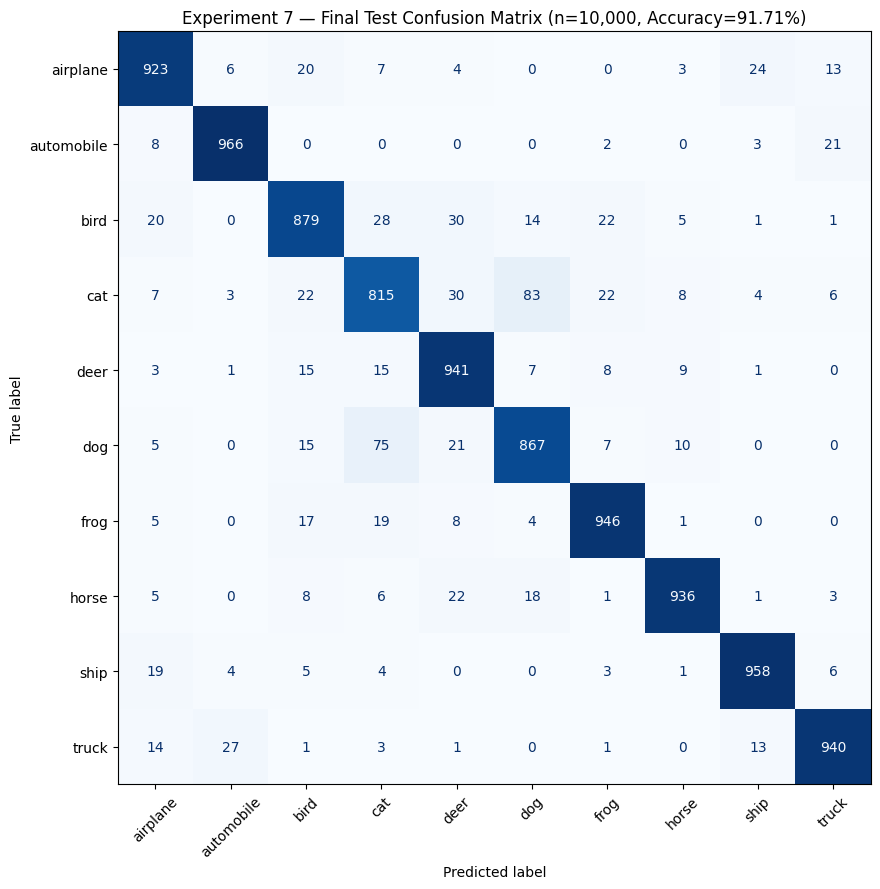

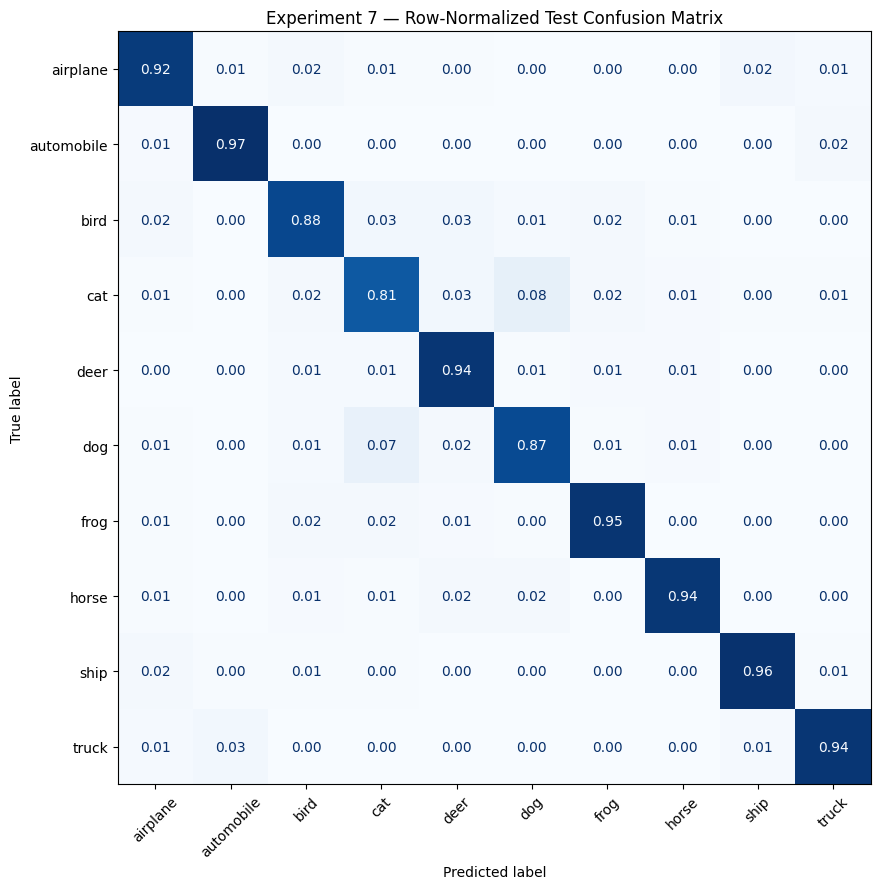

Final test classification report:
              precision    recall  f1-score   support

    airplane       0.91      0.92      0.92      1000
  automobile       0.96      0.97      0.96      1000
        bird       0.90      0.88      0.89      1000
         cat       0.84      0.81      0.83      1000
        deer       0.89      0.94      0.91      1000
         dog       0.87      0.87      0.87      1000
        frog       0.93      0.95      0.94      1000
       horse       0.96      0.94      0.95      1000
        ship       0.95      0.96      0.96      1000
       truck       0.95      0.94      0.94      1000

    accuracy                           0.92     10000
   macro avg       0.92      0.92      0.92     10000
weighted avg       0.92      0.92      0.92     10000



In [7]:
# Metrics 2 — Confusion Matrix (counts + normalized) and per-class performance
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

cm7 = confusion_matrix(y_true7, y_pred7, labels=np.arange(10))
assert cm7.shape == (10, 10)
assert int(cm7.sum()) == 10_000
assert np.array_equal(cm7.sum(axis=1), np.full(10, 1000))
assert abs(100.0 * np.trace(cm7) / cm7.sum() - final_test_acc7) < 1e-10

fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(confusion_matrix=cm7, display_labels=classes7).plot(
    ax=ax, cmap='Blues', values_format='d', xticks_rotation=45, colorbar=False
)
ax.set_title(f'Experiment 7 — Final Test Confusion Matrix (n=10,000, Accuracy={final_test_acc7:.2f}%)')
fig.tight_layout()
fig.savefig(OUTPUT_DIR_7 / 'exp7_confusion_matrix_counts.png', dpi=200, bbox_inches='tight')
plt.show()

cm7_normalized = confusion_matrix(y_true7, y_pred7, labels=np.arange(10), normalize='true')
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay(confusion_matrix=cm7_normalized, display_labels=classes7).plot(
    ax=ax, cmap='Blues', values_format='.2f', xticks_rotation=45, colorbar=False
)
ax.set_title('Experiment 7 — Row-Normalized Test Confusion Matrix')
fig.tight_layout()
fig.savefig(OUTPUT_DIR_7 / 'exp7_confusion_matrix_normalized.png', dpi=200, bbox_inches='tight')
plt.show()

report7 = classification_report(y_true7, y_pred7, labels=np.arange(10),
                                target_names=classes7, output_dict=True, zero_division=0)
per_class7 = pd.DataFrame(report7).T
per_class7.to_csv(OUTPUT_DIR_7 / 'exp7_classification_report.csv')
pd.DataFrame(cm7, index=classes7, columns=classes7).to_csv(
    OUTPUT_DIR_7 / 'exp7_confusion_matrix_counts.csv'
)
print('Final test classification report:')
print(classification_report(y_true7, y_pred7, labels=np.arange(10),
                            target_names=classes7, zero_division=0))

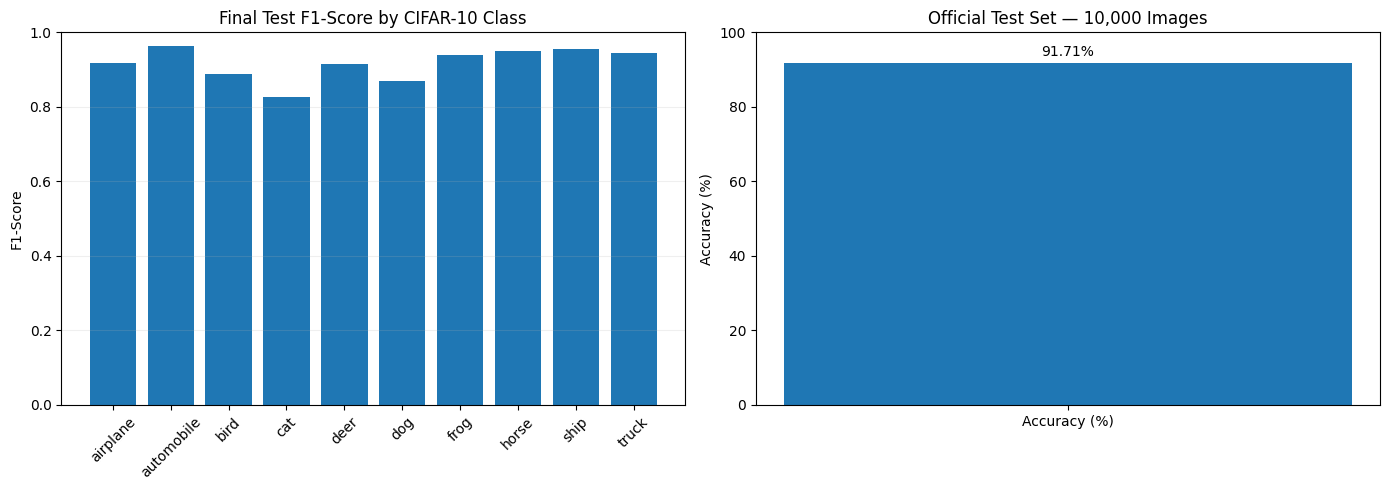

Final Test Loss = 0.3219; Final Test Accuracy = 91.71%


In [8]:
# Metrics 3 — Final per-class F1 and test result card
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
class_f1 = [report7[name]['f1-score'] for name in classes7]
axs[0].bar(classes7, class_f1)
axs[0].set(title='Final Test F1-Score by CIFAR-10 Class', ylabel='F1-Score', ylim=(0, 1))
axs[0].tick_params(axis='x', rotation=45)
axs[0].grid(axis='y', alpha=0.2)

axs[1].bar(['Accuracy (%)'], [final_test_acc7])
axs[1].set(title=f'Official Test Set — {len(y_true7):,} Images', ylabel='Accuracy (%)', ylim=(0, 100))
axs[1].text(0, min(final_test_acc7 + 2, 99), f'{final_test_acc7:.2f}%', ha='center')
fig.tight_layout()
fig.savefig(OUTPUT_DIR_7 / 'exp7_final_per_class_and_accuracy.png', dpi=200, bbox_inches='tight')
plt.show()
print(f'Final Test Loss = {final_test_loss7:.4f}; Final Test Accuracy = {final_test_acc7:.2f}%')

### Historical Comparison — Interpret with Care

Experiments 1–6 were run using earlier procedures that inspected test performance repeatedly and used the full 50,000 original training images. The **corrected Experiment 7** uses 45,000 training + 5,000 validation images and tests **once**. This table is a descriptive comparison of recorded results, **not** a controlled ablation study. Do not call the historical best-test-per-epoch result the final independent test result.

**Note for Task 5:** Test-curve results were monitored per epoch only because the assignment explicitly requests them. Keep the chosen checkpoint based on Validation, not on the highest Test curve point.

,Experiment,Epochs,Batch Size,Final Test Accuracy (%)
0,Exp 1 - Baseline (historical),3,32,67.75
1,Exp 2 - Batch Size 64 (historical),3,64,68.23
2,Exp 3 - LR 0.0005 (historical),3,32,68.75
3,Exp 4 - Deeper CNN (historical),3,32,71.47
4,Exp 5 - Deeper CNN Tuned (historical),3,64,65.23
5,Exp 6 - Extended Training (historical),10,32,78.25
6,Exp 7 - CNN_BN + Validation (new),30,128,91.71


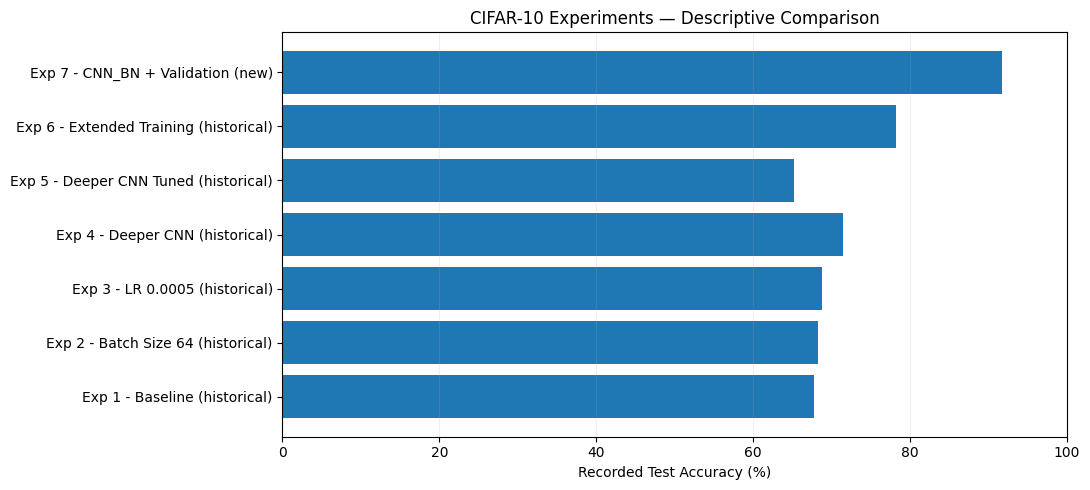

Corrected Exp 7 result = 91.71%; historical teammate Exp 7 = 92.36% (not directly comparable)


In [9]:
# Metrics 4 — Compare historical results with the newly verified Exp 7 result
comparison_data7 = [
    ('Exp 1 - Baseline (historical)', 3, 32, 67.75),
    ('Exp 2 - Batch Size 64 (historical)', 3, 64, 68.23),
    ('Exp 3 - LR 0.0005 (historical)', 3, 32, 68.75),
    ('Exp 4 - Deeper CNN (historical)', 3, 32, 71.47),
    ('Exp 5 - Deeper CNN Tuned (historical)', 3, 64, 65.23),
    ('Exp 6 - Extended Training (historical)', 10, 32, 78.25),
    ('Exp 7 - CNN_BN + Validation (new)', EPOCHS_7, BATCH_7, final_test_acc7),
]
comparison_df7 = pd.DataFrame(comparison_data7,
                              columns=['Experiment', 'Epochs', 'Batch Size', 'Final Test Accuracy (%)'])
comparison_df7.to_csv(OUTPUT_DIR_7 / 'exp7_historical_comparison.csv', index=False)
try:
    display(comparison_df7.round(2))
except NameError:
    print(comparison_df7.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(comparison_df7['Experiment'], comparison_df7['Final Test Accuracy (%)'])
ax.set(xlabel='Recorded Test Accuracy (%)', title='CIFAR-10 Experiments — Descriptive Comparison', xlim=(0, 100))
ax.grid(axis='x', alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR_7 / 'exp7_historical_comparison.png', dpi=200, bbox_inches='tight')
plt.show()
print(f"Corrected Exp 7 result = {final_test_acc7:.2f}%; historical teammate Exp 7 = 92.36% (not directly comparable)")

In [10]:
# Metrics 5 — Reproducibility checks and packaged figures / data for the report
assert len(train_set7) == 45_000
assert len(val_set7) == 5_000
assert len(test_loader7.dataset) == 10_000
assert not set(train_idx7).intersection(set(val_idx7))
assert cm7.sum() == 10_000
assert len(exp7_history['test_loss']) == EPOCHS_7
assert len(exp7_history['test_accuracy']) == EPOCHS_7
assert abs(float(metrics_df7.loc[metrics_df7['epoch'] == best_epoch7, 'test_accuracy'].iloc[0]) - final_test_acc7) < 1e-9
assert (OUTPUT_DIR_7 / 'exp7_REQUIRED_train_test_curves.png').exists()
assert abs(100 * np.trace(cm7) / cm7.sum() - final_test_acc7) < 1e-10
print('PASS — train/validation indices do not overlap.')
print('PASS — each epoch Test metric covers all 10,000 images; final test metrics are from validation-selected epoch.')
print('PASS — confusion matrix matches final test accuracy.')

import shutil
zip_file7 = shutil.make_archive(str(OUTPUT_DIR_7), 'zip', root_dir=OUTPUT_DIR_7)
print('Figures + CSV + final model checkpoint saved in:', OUTPUT_DIR_7.resolve())
print('Results ZIP:', zip_file7)
# To download from Colab (optional):
# from google.colab import files
# files.download(zip_file7)

PASS — train/validation indices do not overlap.
PASS — each epoch Test metric covers all 10,000 images; final test metrics are from validation-selected epoch.
PASS — confusion matrix matches final test accuracy.
Figures + CSV + final model checkpoint saved in: /content/exp7_validation_results
Results ZIP: /content/exp7_validation_results.zip


### Short English report discussion (fill the new results after this rerun)

> We trained a six-convolution CNN with Batch Normalization and Dropout for 30 epochs using AdamW, OneCycleLR, and label smoothing on CIFAR-10. We used 45,000 training images and 5,000 separate validation images, while the official test set contained 10,000 images. Training loss, test loss, and test accuracy were recorded at each epoch to produce the required learning curves. **Only validation accuracy** determined the selected checkpoint; test measurements were not used for model selection or tuning. We then reported the selected model's final test accuracy and loss, confusion matrix, and class-wise F1 scores. Because the test set was monitored after each epoch for visualization, it should not be regarded as wholly unseen throughout development.

Replace with the *actual new run's* best validation epoch, Validation Accuracy, Final Test Accuracy, and Final Test Loss. Do not reuse 91.71% unless this run prints 91.71% again.


### Final checklist — screenshot/save these files

1. `exp7_REQUIRED_train_test_curves.png` — all 3 **required** Task 5 plots.
2. `exp7_train_loss_curve.png`, `exp7_test_loss_curve.png`, `exp7_test_accuracy_curve.png` — plots separately.
3. `exp7_train_validation_curves.png` — clean Train/Validation curves (additional).
4. `exp7_confusion_matrix_counts.png` and `exp7_confusion_matrix_normalized.png`.
5. `exp7_final_per_class_and_accuracy.png` and `exp7_historical_comparison.png`.
6. `exp7_epoch_metrics.csv`, `exp7_final_results.json`, and `exp7_best_validation_model.pt`.

Files are saved in `exp7_validation_results/`; the final code cell creates a ZIP. **Run the whole notebook** to regenerate the per-epoch Test curves—running only these plotting cells on the previous notebook cannot create missing epoch data.
